# Tugas Praktikum 2 — Praproses Data
**Nama:** Firdaus Mangkona · **NRP:** 5054251003

# Tugas Praktikum 2 — Praproses Data
**Dataset:** House Prices – Advanced Regression Techniques (Kaggle) · `train.csv` (1460 baris × 81 kolom)

Tahapan yang dilakukan sesuai modul:
1. Unduh & impor dataset
2. Pembersihan data (nilai hilang, data tidak konsisten)
3. Deteksi & penanganan outlier
4. Transformasi data (standardisasi + one-hot encoding)
5. Reduksi dimensi (korelasi + PCA)
6. Penyimpanan dataset akhir


## 1. Import Dataset & Eksplorasi Awal

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
sns.set_theme(style="whitegrid")

df = pd.read_csv("data/train.csv")
print("Shape:", df.shape)
df.head()

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# Struktur data: tipe kolom & jumlah nilai non-null
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [3]:
# Statistik deskriptif kolom numerik
df.describe().round(2)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.00,1460.0,1201.00,1460.00,1460.00,1460.00,1460.00,1460.00,1452.00,1460.00,...,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.0
mean,730.50,56.9,70.05,10516.83,6.10,5.58,1971.27,1984.87,103.69,443.64,...,94.24,46.66,21.95,3.41,15.06,2.76,43.49,6.32,2007.82,180921.2
std,421.61,42.3,24.28,9981.26,1.38,1.11,30.20,20.65,181.07,456.10,...,125.34,66.26,61.12,29.32,55.76,40.18,496.12,2.70,1.33,79442.5
min,1.00,20.0,21.00,1300.00,1.00,1.00,1872.00,1950.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,2006.00,34900.0
25%,365.75,20.0,59.00,7553.50,5.00,5.00,1954.00,1967.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,5.00,2007.00,129975.0
50%,730.50,50.0,69.00,9478.50,6.00,5.00,1973.00,1994.00,0.00,383.50,...,0.00,25.00,0.00,0.00,0.00,0.00,0.00,6.00,2008.00,163000.0
75%,1095.25,70.0,80.00,11601.50,7.00,6.00,2000.00,2004.00,166.00,712.25,...,168.00,68.00,0.00,0.00,0.00,0.00,0.00,8.00,2009.00,214000.0
max,1460.00,190.0,313.00,215245.00,10.00,9.00,2010.00,2010.00,1600.00,5644.00,...,857.00,547.00,552.00,508.00,480.00,738.00,15500.00,12.00,2010.00,755000.0


**Temuan awal:** dataset memiliki 1460 baris dan 81 kolom. Terdapat 38 kolom numerik
dan 43 kolom kategorikal (object). Target adalah `SalePrice` (harga rumah). Kolom `Id`
hanya berupa penanda baris sehingga akan dibuang saat praproses.

## 2. Pembersihan Data

### 2.1 Cek Nilai Hilang

In [4]:
# Jumlah nilai hilang per atribut (diurutkan menurun)
missing = df.isnull().sum()
missing_sorted = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing_sorted / len(df) * 100).round(2)

print("Jumlah total nilai hilang:", int(df.isnull().sum().sum()))
print(pd.DataFrame({"jumlah_hilang": missing_sorted, "persen": missing_pct}))

Jumlah total nilai hilang: 7829
              jumlah_hilang  persen
PoolQC                 1453   99.52
MiscFeature            1406   96.30
Alley                  1369   93.77
Fence                  1179   80.75
MasVnrType              872   59.73
FireplaceQu             690   47.26
LotFrontage             259   17.74
GarageType               81    5.55
GarageYrBlt              81    5.55
GarageFinish             81    5.55
GarageQual               81    5.55
GarageCond               81    5.55
BsmtExposure             38    2.60
BsmtFinType2             38    2.60
BsmtQual                 37    2.53
BsmtCond                 37    2.53
BsmtFinType1             37    2.53
MasVnrArea                8    0.55
Electrical                1    0.07


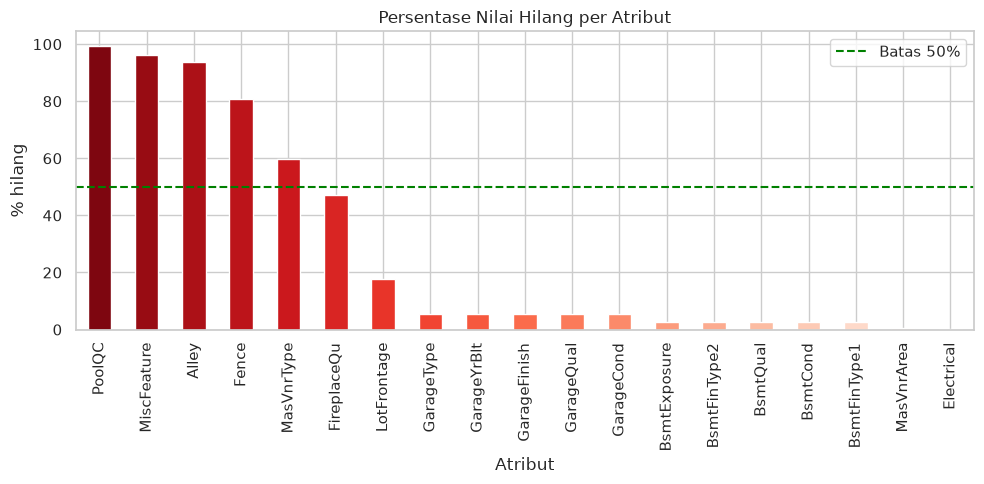

In [5]:
# Visualisasi persentase nilai hilang
fig, ax = plt.subplots(figsize=(10, 5))
missing_pct.plot(kind="bar", color=sns.color_palette("Reds_r", len(missing_pct)), ax=ax)
ax.axhline(50, color="green", ls="--", lw=1.5, label="Batas 50%")
ax.set_title("Persentase Nilai Hilang per Atribut")
ax.set_ylabel("% hilang"); ax.set_xlabel("Atribut"); ax.legend()
plt.tight_layout(); plt.show()

### 2.2 Hapus Atribut dengan Nilai Hilang > 50%

Atribut yang lebih dari 50% kosong: `PoolQC` (99.52%), `MiscFeature` (96.30%),
`Alley` (93.77%), `Fence` (80.75%), dan `MasVnrType` (59.73%).

> **Catatan:** pada dataset ini sebagian besar nilai `NA` sebenarnya bermakna
> *"tidak memiliki fitur tersebut"* (mis. `PoolQC = NA` berarti "tidak ada kolam").
> Karena isinya nyaris seragam (satu kategori mendominasi > 50%), informasi yang
> dibawa sangat kecil sehingga aman dibuang sesuai ketentuan praktikum.

In [6]:
# Pisahkan target terlebih dahulu, lalu hapus kolom >50% hilang
target = "SalePrice"
y = df[target].copy()
X = df.drop(columns=[target])

drop_cols = missing_pct[missing_pct > 50].index.tolist()
print("Kolom yang dihapus:", drop_cols)
X = X.drop(columns=drop_cols)
print("Shape setelah hapus kolom:", X.shape)

Kolom yang dihapus: ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType']
Shape setelah hapus kolom: (1460, 75)


### 2.3 Tangani Nilai Hilang yang Tersisa

In [7]:
# Kategorikal: NA bermakna "tidak ada fitur" -> diisi "None"
na_none = ["FireplaceQu", "BsmtQual", "BsmtCond", "BsmtExposure",
           "BsmtFinType1", "BsmtFinType2", "GarageType",
           "GarageFinish", "GarageQual", "GarageCond"]
for c in na_none:
    X[c] = X[c].fillna("None")

# Electrical: hanya 1 nilai hilang -> modus
X["Electrical"] = X["Electrical"].fillna(X["Electrical"].mode()[0])

# Numerik
X["LotFrontage"] = X["LotFrontage"].fillna(X["LotFrontage"].median())  # median (skewed)
X["MasVnrArea"]  = X["MasVnrArea"].fillna(0)                            # 0 = tanpa veneer
X["GarageYrBlt"] = X["GarageYrBlt"].fillna(X["YearBuilt"])              # tanpa garasi -> pakai tahun rumah

print("Sisa nilai hilang:", int(X.isnull().sum().sum()))

Sisa nilai hilang: 0


In [8]:
# Cek konsistensi data
print("Baris duplikat (Id):", int(df["Id"].duplicated().sum()))
print("Nilai negatif pada kolom numerik:",
      {c: int((df[c] < 0).sum()) for c in df.select_dtypes(include=np.number).columns if (df[c] < 0).any()})
print("YearBuilt > YrSold :", int((df["YearBuilt"] > df["YrSold"]).sum()))
print("GarageCars=0 tapi GarageArea>0 :", int(((df["GarageCars"] == 0) & (df["GarageArea"] > 0)).sum()))
print("GarageArea=0 tapi GarageType terisi:", int(((df["GarageArea"] == 0) & (df["GarageType"].notna())).sum()))

Baris duplikat (Id): 0
Nilai negatif pada kolom numerik: {}
YearBuilt > YrSold : 0
GarageCars=0 tapi GarageArea>0 : 0
GarageArea=0 tapi GarageType terisi: 0


Setelah pembersihan: **0 nilai hilang**, tidak ada duplikat, tidak ada nilai negatif,
dan tidak ditemukan inkonsistensi (tahun dibangun ≤ tahun terjual, data garasi konsisten).

## 3. Deteksi & Penanganan Outlier

### 3.1 Deteksi dengan Boxplot & IQR

In [9]:
# Fitur kontinu (luas/area) yang diperiksa outlier-nya
cont = ["LotFrontage", "LotArea", "MasVnrArea", "BsmtFinSF1", "BsmtFinSF2",
        "BsmtUnfSF", "TotalBsmtSF", "1stFlrSF", "2ndFlrSF", "LowQualFinSF",
        "GrLivArea", "GarageArea", "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
        "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal"]
cont_present = [c for c in cont if c in X.columns]

def n_outliers(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return int(((s < lo) | (s > hi)).sum())

out_count = {c: n_outliers(X[c]) for c in cont_present}
print("Jumlah outlier (IQR 1.5) per fitur:")
print(out_count)
print("Total flag outlier:", sum(out_count.values()))

Jumlah outlier (IQR 1.5) per fitur:
{'LotFrontage': 106, 'LotArea': 69, 'MasVnrArea': 98, 'BsmtFinSF1': 7, 'BsmtFinSF2': 167, 'BsmtUnfSF': 29, 'TotalBsmtSF': 61, '1stFlrSF': 20, '2ndFlrSF': 2, 'LowQualFinSF': 26, 'GrLivArea': 31, 'GarageArea': 21, 'WoodDeckSF': 32, 'OpenPorchSF': 77, 'EnclosedPorch': 208, '3SsnPorch': 24, 'ScreenPorch': 116, 'PoolArea': 7, 'MiscVal': 52}
Total flag outlier: 1153


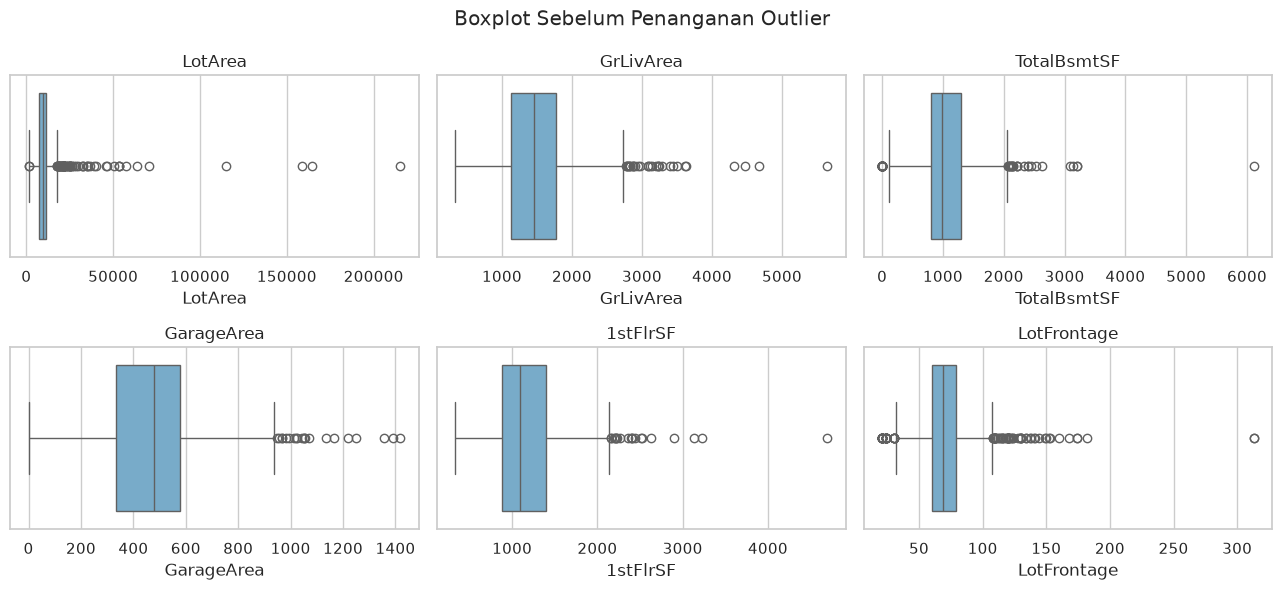

In [10]:
sel = ["LotArea", "GrLivArea", "TotalBsmtSF", "GarageArea", "1stFlrSF", "LotFrontage"]
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), sel):
    sns.boxplot(x=X[c], ax=ax, color="#6baed6")
    ax.set_title(c)
plt.suptitle("Boxplot Sebelum Penanganan Outlier")
plt.tight_layout(); plt.show()

### 3.2 Penanganan Outlier (Winsorizing)

**Keputusan: outlier *disesuaikan (dicap)*, bukan dihapus.** Alasannya:
dataset hanya 1460 baris; menghapus outlier akan membuang data berharga
(rumah-rumah besar/istimewa yang tetap merupakan data sah). Winsorizing menahan
nilai ekstrem pada batas **Q1 − 1.5·IQR** dan **Q3 + 1.5·IQR** sehingga distribusi
lebih normal tanpa kehilangan observasi.

In [11]:
for c in cont_present:
    q1, q3 = X[c].quantile(0.25), X[c].quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    X[c] = X[c].clip(lo, hi)

print("Sisa outlier setelah winsorizing:",
      sum(n_outliers(X[c]) for c in cont_present))

Sisa outlier setelah winsorizing: 0


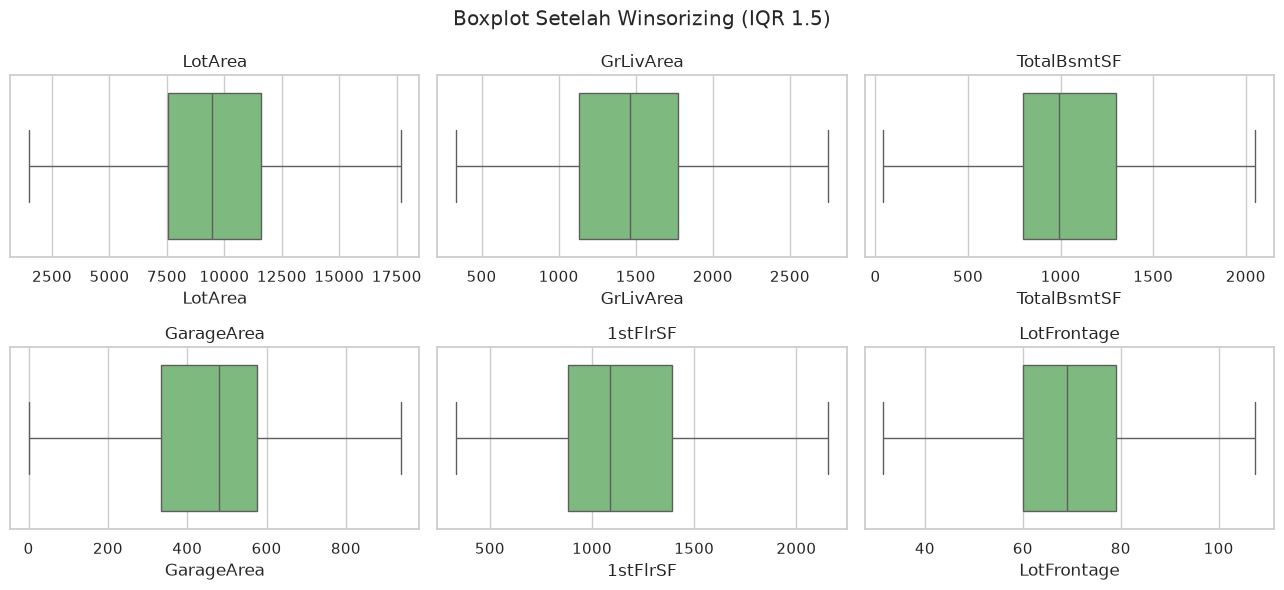

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), sel):
    sns.boxplot(x=X[c], ax=ax, color="#74c476")
    ax.set_title(c)
plt.suptitle("Boxplot Setelah Winsorizing (IQR 1.5)")
plt.tight_layout(); plt.show()

## 4. Transformasi Data

### 4.1 Standardisasi Kolom Numerik & One-Hot Encoding Kolom Kategorikal

In [13]:
# Buang Id (penanda baris, bukan fitur)
X = X.drop(columns=["Id"])

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Jumlah kolom numerik :", len(num_cols))
print("Jumlah kolom kategorikal:", len(cat_cols))

Jumlah kolom numerik : 36
Jumlah kolom kategorikal: 38


In [14]:
# One-hot encoding (drop_first=True untuk menghindari multikolinearitas dummy)
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print("Shape setelah one-hot encoding:", X_enc.shape)

Shape setelah one-hot encoding: (1460, 243)


In [15]:
# Standardisasi (z-score) seluruh kolom numerik
scaler = StandardScaler()
X_scaled = X_enc.copy()
X_scaled[num_cols] = scaler.fit_transform(X_enc[num_cols])
print("Shape dataset hasil transformasi:", X_scaled.shape)
X_scaled.head()

Shape dataset hasil transformasi: (1460, 243)


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_ConLI,SaleType_ConLw,SaleType_New,SaleType_Oth,SaleType_WD,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial
0,0.073375,-0.237456,-0.333244,0.651479,-0.517200,1.050994,0.878668,0.795643,0.614224,0.0,...,False,False,False,False,True,False,False,False,True,False
1,-0.872563,0.633321,-0.013189,-0.071836,2.179628,0.156734,-0.429577,-0.667353,1.242296,0.0,...,False,False,False,False,True,False,False,False,True,False
2,0.073375,-0.063300,0.446022,0.651479,-0.517200,0.984752,0.830215,0.541858,0.106224,0.0,...,False,False,False,False,True,False,False,False,True,False
3,0.309859,-0.527714,-0.027104,0.651479,-0.517200,-1.863632,-0.720298,-0.667353,-0.517230,0.0,...,False,False,False,False,True,False,False,False,False,False
4,0.073375,0.865528,1.283733,1.374795,-0.517200,0.951632,0.733308,1.945140,0.496460,0.0,...,False,False,False,False,True,False,False,False,True,False


Kolom ordinal/integer (mis. `OverallQual`, tahun, jumlah kamar) tetap diperlakukan
numerik karena punya urutan alami. `StandardScaler` dipilih karena cocok untuk PCA
dan distribusi data setelah winsorizing sudah relatif simetris.

## 5. Reduksi Dimensi

### 5.1 Analisis Korelasi & Pembuangan Atribut Redundan

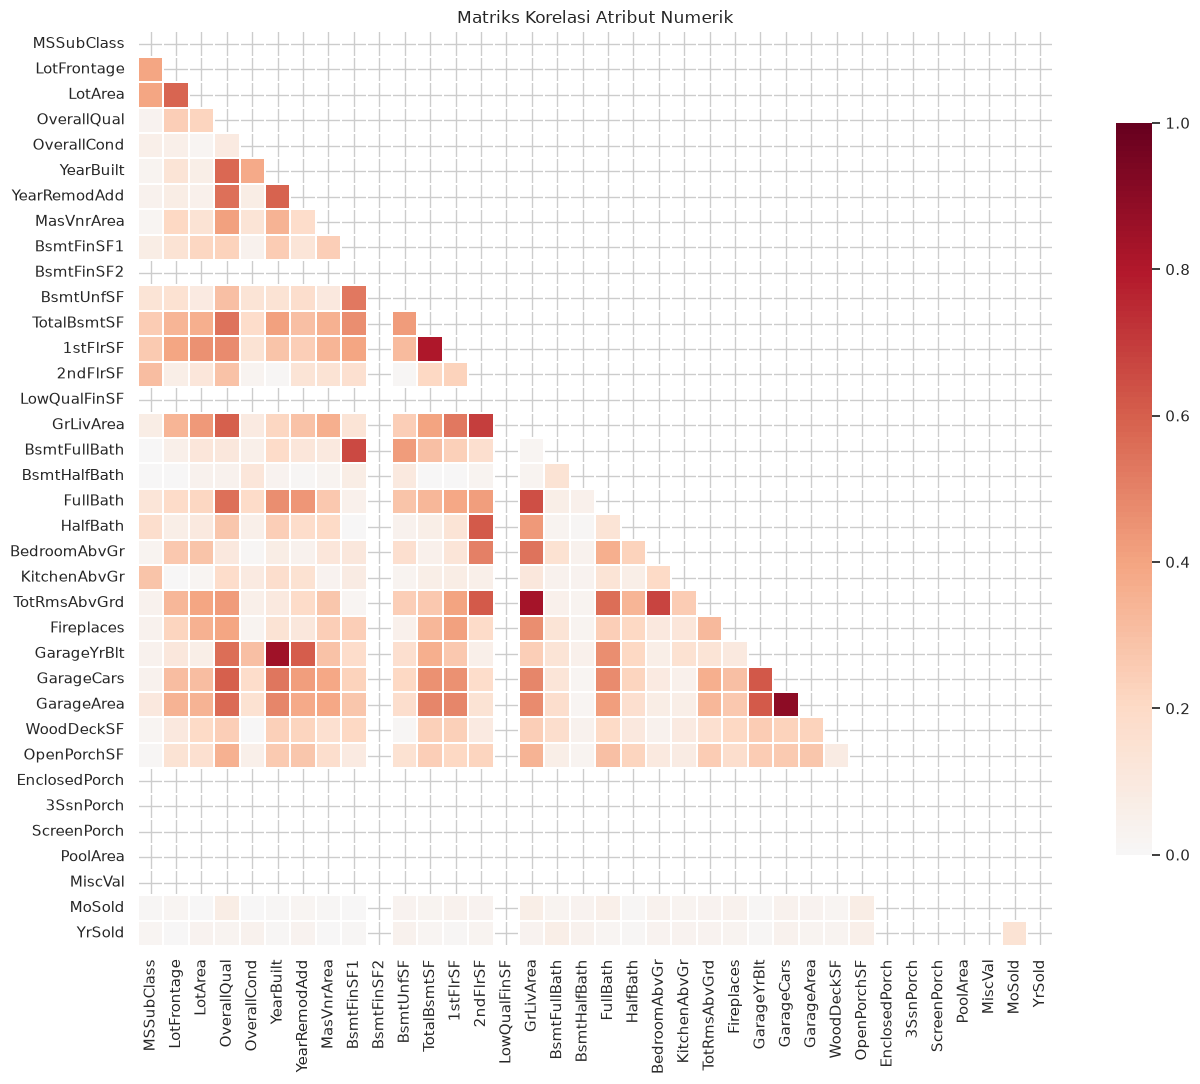

In [16]:
corr = X[num_cols].corr().abs()

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=0, vmax=1,
            square=True, linewidths=0.3, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Matriks Korelasi Atribut Numerik")
plt.tight_layout(); plt.show()

In [17]:
# Pasangan atribut dengan korelasi > 0.8
high_pairs = []
for i in range(len(corr.columns)):
    for j in range(i):
        r = corr.iloc[i, j]
        if r > 0.8:
            high_pairs.append((corr.columns[i], corr.columns[j], round(r, 3)))
high_pairs.sort(key=lambda x: -x[2])
print("Pasangan berkorelasi tinggi (|r| > 0.8):")
for a, b, r in high_pairs:
    print(f"  {a} <-> {b}: {r}")

Pasangan berkorelasi tinggi (|r| > 0.8):
  GarageArea <-> GarageCars: 0.893
  GarageYrBlt <-> YearBuilt: 0.845
  TotRmsAbvGrd <-> GrLivArea: 0.836
  1stFlrSF <-> TotalBsmtSF: 0.807


In [18]:
# Buang satu atribut dari tiap pasangan yang sangat berkorelasi
drop_corr = ["GarageCars", "GarageYrBlt", "TotRmsAbvGrd"]
print("Atribut yang dibuang:", drop_corr)
X = X.drop(columns=drop_corr)
num_cols = [c for c in num_cols if c not in drop_corr]

Atribut yang dibuang: ['GarageCars', 'GarageYrBlt', 'TotRmsAbvGrd']


Alasan pemilihan atribut yang dibuang:
- `GarageCars` ↔ `GarageArea` (0.893): jumlah mobil kurang granular daripada luas, buang `GarageCars`.
- `GarageYrBlt` ↔ `YearBuilt` (0.845): informasi tahun garasi tumpang tindih, buang `GarageYrBlt`.
- `TotRmsAbvGrd` ↔ `GrLivArea` (0.836): jumlah kamar sangat redundan dengan luas, buang `TotRmsAbvGrd`.

`1stFlrSF` ↔ `TotalBsmtSF` (0.807) *dipertahankan* karena mengukur bagian rumah
yang berbeda (lantai 1 vs basement).

> Karena `GarageCars`, `GarageYrBlt`, `TotRmsAbvGrd` sudah dibuang, one-hot encoding
> dan standardisasi dijalankan ulang pada set fitur yang sudah direduksi.

In [19]:
X_enc = pd.get_dummies(X, columns=cat_cols, drop_first=True)
X_scaled = X_enc.copy()
X_scaled[num_cols] = scaler.fit_transform(X_enc[num_cols])
print("Shape fitur akhir (sebelum PCA):", X_scaled.shape)

Shape fitur akhir (sebelum PCA): (1460, 240)


### 5.2 Principal Component Analysis (PCA)

Komponen untuk mempertahankan 95% varians: 66 (varians 0.9508)


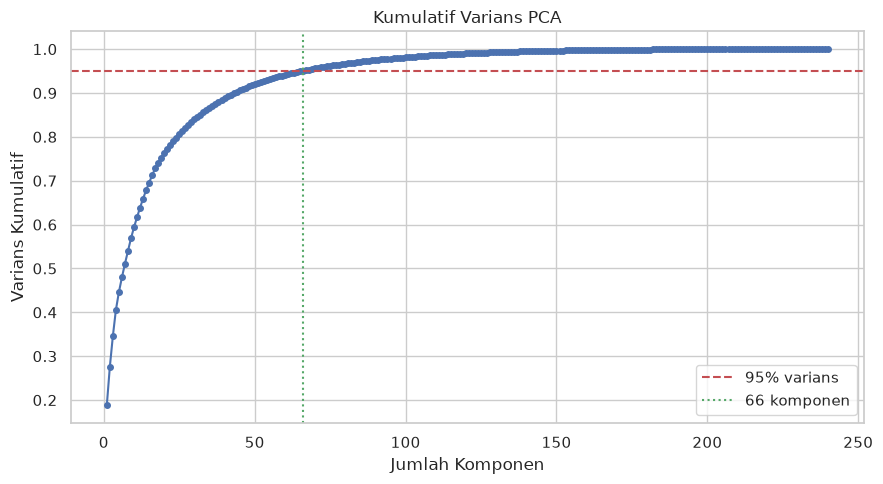

In [20]:
pca_full = PCA()
pca_full.fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)

n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"Komponen untuk mempertahankan 95% varians: {n95} (varians {cum[n95-1]:.4f})")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(cum) + 1), cum, marker="o", ms=4)
ax.axhline(0.95, color="r", ls="--", label="95% varians")
ax.axvline(n95, color="g", ls=":", label=f"{n95} komponen")
ax.set_xlabel("Jumlah Komponen"); ax.set_ylabel("Varians Kumulatif")
ax.set_title("Kumulatif Varians PCA")
ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

In [21]:
pca = PCA(n_components=n95)
X_pca = pca.fit_transform(X_scaled)
X_pca_df = pd.DataFrame(X_pca, columns=[f"PC{i+1}" for i in range(n95)],
                        index=X_scaled.index)
print("Shape setelah PCA:", X_pca_df.shape)

Shape setelah PCA: (1460, 66)


**Hasil reduksi dimensi:** dari 240 fitur hasil encoding, PCA berhasil meringkas
menjadi **66 komponen utama** yang sudah mempertahankan **95%** varians data
(atau 44 komponen untuk 90% varians).

## 6. Simpan Dataset Akhir

In [22]:
# Dataset akhir yang dikumpulkan = fitur hasil scaling + one-hot + target SalePrice
final = pd.concat([X_scaled.reset_index(drop=True), y.reset_index(drop=True)], axis=1)
final.to_csv("5054251003_Firdaus_Mangkona_Tugas_Praproses_Data.csv", index=False)
print("Dataset akhir (scaled + one-hot):", final.shape)

# Versi hasil PCA (opsional, untuk dokumentasi reduksi dimensi)
final_pca = pd.concat([X_pca_df.reset_index(drop=True), y.reset_index(drop=True)], axis=1)
final_pca.to_csv("5054251003_Firdaus_Mangkona_Tugas_Praproses_Data_pca.csv", index=False)
print("Dataset hasil PCA:", final_pca.shape)

Dataset akhir (scaled + one-hot): (1460, 241)


Dataset hasil PCA: (1460, 67)


## Ringkasan
| Tahap | Sebelum | Sesudah |
|---|---|---|
| Nilai hilang | 7.829 nilai | 0 |
| Kolom dibuang (>50% hilang) | — | 5 kolom |
| Outlier (IQR 1.5) | 1.153 flag | 0 (winsorizing) |
| Fitur setelah encoding | 80 kolom fitur | 240 fitur |
| Fitur setelah reduksi korelasi | — | −3 fitur |
| Fitur setelah PCA (95% var.) | 240 | 66 komponen |

**Dataset akhir siap digunakan** untuk pemodelan machine learning.